# 07 · Graph-Enhanced ML Model (Experiment B)
Question: **does information extracted from the knowledge graph add measurable predictive value?**

Experiment B = Experiment A's features + the 9 graph features exported from Neo4j in notebook 05.
Everything else is identical: split, folds, tree settings, threshold procedure. So any difference comes from the graph features alone.

We decided in advance: B counts as better only if the confidence interval of the improvement excludes zero. A "no improvement" result is reported as it is.

**Setup.**

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from credit_kg import config as C
import json, pickle
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import brier_score_loss
from sklearn.inspection import permutation_importance
from credit_kg import modeling as M, features as F

**Load data and reuse the tree settings chosen in notebook 06** (no re-tuning for B, which keeps the comparison fair).

In [2]:
table = M.load_table()
params = json.load(open(C.MODELS / "rf_params.json"))
def rf():
    m = M.make_rf(params["min_samples_leaf"]); m.set_params(max_features=params["max_features"]); return m
X_A, y, Xt_A, yt, ids_tr, ids_te = M.matrices(table, "A")
X_B, _, Xt_B, _, _, _ = M.matrices(table, "B")   # fails loudly if graph features are missing or constant
print("A:", X_A.shape[1], "features | B:", X_B.shape[1], "features")
print("added by the graph:", [c for c in X_B.columns if c not in X_A.columns])

A: 37 features | B: 46 features
added by the graph: ['g_max_late_streak', 'g_late_onsets', 'g_recoveries', 'g_relapses', 'g_latest_transition', 'g_max_util_rise_run', 'g_weak_cov_after_late', 'g_markov_next_late_prob', 'g_path_typicality']


**Repeated cross-validation on the same 25 folds** as notebook 06, for:
* `B`: baseline + all 9 graph features;
* `B_no_population`: without the two population features (the transition-network probabilities);
* `graph_only`: credit limit + graph features only (how much the graph features know on their own).

In [3]:
cv = {"A": pd.read_csv(C.TABLES / "cv_folds_A.csv")}
for name in ["B", "B_no_population", "graph_only"]:
    cv[name] = M.repeated_cv(M.matrices(table, name)[0], y, rf)
    cv[name].to_csv(C.TABLES / f"cv_folds_{name}.csv", index=False)
pd.DataFrame({k: {"roc_auc_mean": v.roc_auc.mean(), "roc_auc_sd": v.roc_auc.std(), "pr_auc_mean": v.pr_auc.mean()} for k, v in cv.items()}).T.round(4)

,roc_auc_mean,roc_auc_sd,pr_auc_mean
A,0.7880,0.0067,0.5612
B,0.7879,0.0068,0.5611
B_no_population,0.7878,0.0067,0.5610
graph_only,0.7704,0.0070,0.5433


**Fold-by-fold comparison with a corrected t-test.** Each of the 25 folds gives an A score and a B score on the same customers. We test whether B − A is reliably above zero, using a t-test corrected for the overlap between cross-validation folds.

In [4]:
n_tr, n_te = int(len(y) * 0.8), int(len(y) * 0.2)
tests = {}
for name in ["B", "B_no_population"]:
    for metric in ["roc_auc", "pr_auc"]:
        tests[f"{name} - A ({metric})"] = M.corrected_resampled_ttest(cv[name][metric] - cv["A"][metric], n_tr, n_te)
pd.DataFrame(tests).T.round(4)

,mean_diff,folds_b_better,folds,t,p_value
B - A (roc_auc),-0.0001,12.0,25.0,-0.2264,0.8228
B - A (pr_auc),-0.0001,11.0,25.0,-0.1561,0.8772
B_no_population - A (roc_auc),-0.0002,10.0,25.0,-0.4512,0.6559
B_no_population - A (pr_auc),-0.0002,10.0,25.0,-0.2099,0.8355


**Out-of-fold threshold for B**, chosen exactly as for A (best F1 on training predictions).

In [5]:
oof_B = M.oof_proba(X_B, y, rf)
thr_B = M.best_f1_threshold(y, oof_B)
meta_A = json.load(open(C.MODELS / "model_A_meta.json"))
print(f"threshold A = {meta_A['threshold']:.3f}, threshold B = {thr_B:.3f}")

threshold A = 0.522, threshold B = 0.521


**Final fit and single test-set evaluation**, side by side with A.

In [6]:
model_B = rf().fit(X_B, y)
p_B = model_B.predict_proba(Xt_B)[:, 1]
p_A = pd.read_parquet(C.MODELS / "test_pred_A.parquet")["p_A"].to_numpy()
comp = pd.DataFrame({"A (baseline)": M.evaluate(yt, p_A, meta_A["threshold"]), "B (graph-enhanced)": M.evaluate(yt, p_B, thr_B)})
comp["B - A"] = comp["B (graph-enhanced)"] - comp["A (baseline)"]
comp.round(4)

,A (baseline),B (graph-enhanced),B - A
threshold,0.5224,0.5210,-0.0014
roc_auc,0.7800,0.7792,-0.0008
pr_auc,0.5575,0.5566,-0.0009
precision,0.4975,0.5006,0.0031
recall,0.5961,0.6006,0.0045
f1,0.5423,0.5461,0.0037
accuracy,0.7775,0.7792,0.0017
tn,3874.0000,3878.0000,4.0000
fp,799.0000,795.0000,-4.0000
fn,536.0000,530.0000,-6.0000


**Paired bootstrap on the test set.** We resample the 6,000 test customers 2,000 times, score both models on each resample, and look at the spread of the difference. This gives a 95% confidence interval for B − A.

In [7]:
boot = M.paired_bootstrap(yt, p_A, p_B)
print(f"ΔROC-AUC = {boot['delta_roc_auc']:+.4f}  95% CI [{boot['roc_auc_ci'][0]:+.4f}, {boot['roc_auc_ci'][1]:+.4f}]  (share of resamples where B is not better: {boot['p_b_not_better_roc']:.2f})")
print(f"ΔPR-AUC  = {boot['delta_pr_auc']:+.4f}  95% CI [{boot['pr_auc_ci'][0]:+.4f}, {boot['pr_auc_ci'][1]:+.4f}]")

ΔROC-AUC = -0.0008  95% CI [-0.0019, +0.0004]  (share of resamples where B is not better: 0.91)
ΔPR-AUC  = -0.0009  95% CI [-0.0032, +0.0013]


**Verdict**, decided by the rule we set before running: improvement only if the ROC-AUC confidence interval is entirely above zero.

In [8]:
improved = boot["roc_auc_ci"][0] > 0
verdict = ("Graph features give a small but statistically reliable improvement." if improved else
           "No reliable improvement: the graph features do not measurably improve default prediction beyond the baseline.")
print(verdict)

No reliable improvement: the graph features do not measurably improve default prediction beyond the baseline.


**Does B actually use the graph features?** Permutation importance on the test set for B's inputs. The graph features are highlighted.

In [9]:
pi = permutation_importance(model_B, Xt_B, yt, scoring="roc_auc", n_repeats=5, random_state=C.SEED, n_jobs=-1)
imp_B = pd.DataFrame({"auc_drop": pi.importances_mean, "sd": pi.importances_std}, index=Xt_B.columns).sort_values("auc_drop", ascending=False)
imp_B["graph_feature"] = imp_B.index.str.startswith("g_")
imp_B.to_csv(C.TABLES / "importance_B.csv")
imp_B.head(15).round(4)

,auc_drop,sd,graph_feature
bill_m6,0.0040,0.0007,False
util_avg,0.0036,0.0017,False
status_latest,0.0031,0.0009,False
status_m6,0.0028,0.0008,False
high_util_months,0.0024,0.0006,False
max_status,0.0022,0.0009,False
credit_limit,0.0022,0.0010,False
pay_median,0.0019,0.0004,False
util_slope,0.0019,0.0005,False
late_recent3,0.0019,0.0012,False


**Graph features only.** Their importance inside B, all 9. Low values mean the forest found the same information already in the baseline features.

In [10]:
imp_B[imp_B.graph_feature].round(4)

,auc_drop,sd,graph_feature
g_markov_next_late_prob,0.0011,0.0006,True
g_max_late_streak,0.0009,0.0008,True
g_max_util_rise_run,0.0002,0.0001,True
g_weak_cov_after_late,0.0000,0.0005,True
g_latest_transition,0.0000,0.0000,True
g_relapses,-0.0000,0.0000,True
g_late_onsets,-0.0000,0.0001,True
g_recoveries,-0.0000,0.0001,True
g_path_typicality,-0.0001,0.0000,True


**Which probability model feeds the scenario?** Following the rule "prefer the simpler model unless the richer one is reliably better": if B did not improve, we use A (it also does not depend on Neo4j being available).
We then **calibrate** the probabilities (isotonic regression inside cross-validation), so that 0.3 really means about a 30% default rate.

In [11]:
chosen = "B" if improved else "A"
Xc, Xtc = (X_B, Xt_B) if chosen == "B" else (X_A, Xt_A)
cal = lambda: CalibratedClassifierCV(rf(), method="isotonic", cv=5)
pd_train = cross_val_predict(cal(), Xc, y, cv=StratifiedKFold(5, shuffle=True, random_state=C.SEED), method="predict_proba")[:, 1]
cal_model = cal().fit(Xc, y)
pd_test = cal_model.predict_proba(Xtc)[:, 1]
raw_test = (p_B if chosen == "B" else p_A)
print(f"scenario uses model {chosen} | Brier score raw {brier_score_loss(yt, raw_test):.4f} -> calibrated {brier_score_loss(yt, pd_test):.4f}")

scenario uses model A | Brier score raw 0.1732 -> calibrated 0.1346


**Reliability after calibration** (test set). The calibrated line should sit close to the diagonal.

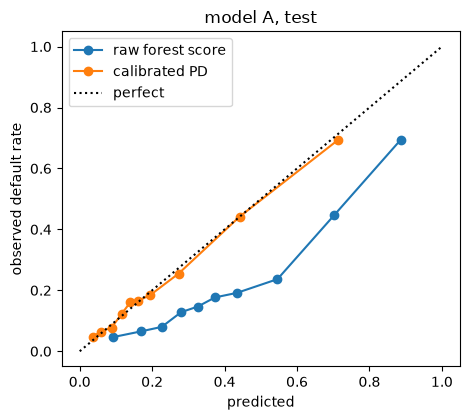

In [12]:
plt.figure(figsize=(4.8, 4.3))
for p, lab in [(raw_test, "raw forest score"), (pd_test, "calibrated PD")]:
    f, m = calibration_curve(yt, p, n_bins=10, strategy="quantile"); plt.plot(m, f, "o-", label=lab)
plt.plot([0, 1], [0, 1], "k:", label="perfect"); plt.xlabel("predicted"); plt.ylabel("observed default rate"); plt.legend(); plt.title(f"model {chosen}, test")
plt.tight_layout(); plt.savefig(C.FIGURES / "calibration_pd.png", dpi=120)

**Save** the comparison and the calibrated default probabilities. Training customers get out-of-fold PDs, so no customer is scored by a model that saw their own outcome.

In [13]:
pickle.dump(model_B, open(C.MODELS / "model_B.pkl", "wb"))
pickle.dump(cal_model, open(C.MODELS / "pd_model.pkl", "wb"))
pd.concat([pd.DataFrame({"customer_id": ids_tr, "pd": pd_train, "split": "train"}),
           pd.DataFrame({"customer_id": ids_te, "pd": pd_test, "split": "test"})]).assign(model=chosen)\
  .to_parquet(C.MODELS / "pd_calibrated.parquet", index=False)
comp.to_csv(C.TABLES / "model_comparison_test.csv")
json.dump({"verdict": verdict, "improved": bool(improved), "pd_model": chosen, "bootstrap": boot, "cv_tests": tests,
           "threshold_B": thr_B, "features_B": list(X_B.columns)}, open(C.MODELS / "comparison.json", "w"), indent=2, default=float)
print("saved")

saved


## Experiment B-LR: do graph features help a simple, interpretable model?
A Random Forest can learn order patterns (streaks, recoveries) from the raw monthly columns by itself. **Logistic regression cannot**: it only adds up weighted features. So we repeat the whole A-vs-B protocol with logistic regression: the same 25 folds, the corrected t-test, the OOF threshold, the test set used once, and the paired bootstrap.

**Logistic regression model** (features standardised; balanced class weights, like the forest).

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
lr = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced"))

**Repeated cross-validation on the same 25 folds**, then the corrected t-test on the fold-by-fold differences.

In [15]:
cv_lr = {name: M.repeated_cv(X_, y, lr) for name, X_ in [("LR-A", X_A), ("LR-B", X_B)]}
for k, v in cv_lr.items(): v.to_csv(C.TABLES / f"cv_folds_{k}.csv", index=False)
lr_tests = {f"LR-B - LR-A ({m})": M.corrected_resampled_ttest(cv_lr["LR-B"][m] - cv_lr["LR-A"][m], n_tr, n_te) for m in ["roc_auc", "pr_auc"]}
display(pd.DataFrame({k: {"roc_auc_mean": v.roc_auc.mean(), "pr_auc_mean": v.pr_auc.mean()} for k, v in cv_lr.items()}).T.round(4))
pd.DataFrame(lr_tests).T.round(4)

,roc_auc_mean,pr_auc_mean
LR-A,0.7665,0.5092
LR-B,0.7717,0.5268


,mean_diff,folds_b_better,folds,t,p_value
LR-B - LR-A (roc_auc),0.0052,24.0,25.0,3.6930,0.0011
LR-B - LR-A (pr_auc),0.0176,25.0,25.0,5.7767,0.0000


**Test set, used once:** OOF thresholds, final fits and the paired bootstrap.

In [16]:
lr_res, lr_p = {}, {}
for name, (Xtr_, Xte_) in {"LR-A": (X_A, Xt_A), "LR-B": (X_B, Xt_B)}.items():
    t_ = M.best_f1_threshold(y, M.oof_proba(Xtr_, y, lr))
    lr_p[name] = lr().fit(Xtr_, y).predict_proba(Xte_)[:, 1]
    lr_res[name] = M.evaluate(yt, lr_p[name], t_)
lr_comp = pd.DataFrame(lr_res); lr_comp["B - A"] = lr_comp["LR-B"] - lr_comp["LR-A"]
lr_boot = M.paired_bootstrap(yt, lr_p["LR-A"], lr_p["LR-B"])
print(f"ΔROC-AUC = {lr_boot['delta_roc_auc']:+.4f}  95% CI [{lr_boot['roc_auc_ci'][0]:+.4f}, {lr_boot['roc_auc_ci'][1]:+.4f}]")
print(f"ΔPR-AUC  = {lr_boot['delta_pr_auc']:+.4f}  95% CI [{lr_boot['pr_auc_ci'][0]:+.4f}, {lr_boot['pr_auc_ci'][1]:+.4f}]")
lr_comp.to_csv(C.TABLES / "model_comparison_lr_test.csv")
json.dump({"cv_tests": lr_tests, "bootstrap": lr_boot, "improved": bool(lr_boot["roc_auc_ci"][0] > 0)},
          open(C.MODELS / "comparison_lr.json", "w"), indent=2, default=float)
lr_comp.round(4)

ΔROC-AUC = +0.0065  95% CI [+0.0027, +0.0101]
ΔPR-AUC  = +0.0176  95% CI [+0.0066, +0.0284]


,LR-A,LR-B,B - A
threshold,0.5559,0.5804,0.0245
roc_auc,0.7573,0.7638,0.0065
pr_auc,0.5021,0.5197,0.0176
precision,0.4827,0.5059,0.0232
recall,0.5576,0.5448,-0.0128
f1,0.5175,0.5247,0.0072
accuracy,0.7700,0.7817,0.0117
tn,3880.0000,3967.0000,87.0000
fp,793.0000,706.0000,-87.0000
fn,587.0000,604.0000,17.0000


**Which graph features does logistic regression lean on?** Standardised coefficients of the graph features in LR-B (positive = pushes towards default).

In [17]:
coef = pd.Series(lr().fit(X_B, y)[-1].coef_[0], index=X_B.columns)
coef[coef.index.str.startswith("g_")].sort_values().round(3).to_frame("standardised coefficient")

,standardised coefficient
g_markov_next_late_prob,-0.656
g_max_late_streak,-0.566
g_recoveries,-0.237
g_weak_cov_after_late,-0.108
g_max_util_rise_run,-0.048
g_relapses,0.001
g_path_typicality,0.161
g_latest_transition,0.400
g_late_onsets,0.435


### Answer to the research question (honest result)
**The graph-derived features did not measurably improve default prediction.**
* Cross-validation, 25 identical folds: A = 0.7880, B = 0.7879 ROC-AUC. B was better in only 12 of 25 folds (corrected t-test p ≈ 0.82).
* Test set: ΔROC-AUC = −0.0008, 95% CI [−0.0019, +0.0004]. ΔPR-AUC is also about zero. F1 moved +0.004, which is within noise.
* Removing the population (transition-network) features changes nothing either.

**Why?** The graph features are *informative but redundant*:
* On their own (`graph_only`: credit limit + 9 graph features) they reach 0.770 ROC-AUC, most of the baseline's 0.788, so they do capture real risk behaviour.
* But the 18 raw monthly columns already contain the full six-month sequence, and the forest learns the order effects (streaks, onsets, recoveries) from them directly. Inside B, the graph features get small importance because the same information is already there.

**But for a simple, interpretable model, the graph features do help (Experiment B-LR).**
* Logistic regression A → B: +0.0052 ROC-AUC in cross-validation (B better in 24 of 25 folds, corrected p = 0.001) and +0.018 PR-AUC in every fold.
* Test set: ΔROC-AUC = +0.0065, 95% CI [+0.0027, +0.0101]; ΔPR-AUC = +0.018, CI [+0.007, +0.028]. **This is a reliable improvement** by our pre-set rule.
* Why: a linear model cannot build "late → recovered → late again" or "state sequence" patterns from raw columns. The graph hands them over as ready-made features.
* Read the LR coefficients with care: graph features overlap strongly with `late_months` and friends, so individual signs (e.g. the negative sign of `g_max_late_streak`) partly correct for that overlap. They are not stand-alone effects.
* The Random Forest (0.788) is still stronger than LR-B (0.772). The graph narrows the gap for the explainable model but does not close it.

**What the graph still contributes** (why it stays in the project):
1. **Evidence and explanation.** Cypher returns human-readable paths ("late 4 months in a row", "recovered in May, late again in August") that notebook 08 attaches to each customer's explanation.
2. **Population structure.** The state-transition network, learned from training customers, is a reusable, inspectable model of how repayment behaviour moves month to month.
3. **A verified, idempotent temporal representation** that other questions can query without re-engineering features.

**For the scenario layer:** following the pre-set rule, the calibrated default probability comes from **model A**. Calibration reduced the Brier score from 0.173 to 0.135.